# 1.5 Línea base clásica

Actividad **1.5**: regresión logística y LightGBM sobre las variables de 1.4, evaluados en **validación**.

Métricas de la Entrega 1:

- PR-AUC
- ROC-AUC
- recall con precisión ≥ 0.80
- matriz de confusión multiclase

## Protocolo

- **Datos:** `data/interim/{train,val}.parquet`. Prueba no se abre.
- **Regresión logística:** imputación con la mediana de train, estandarización ajustada en train, L2 con C = 1.
- **LightGBM:** hiperparámetros fijos. El número de árboles se elige con *early stopping* en un holdout temporal interno de train (jul–ago; ajuste con ene–jun) y luego se reentrena con todo train. Validación no interviene en ningún ajuste.
- Sin ponderación de clases. Semilla 42.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import lightgbm as lgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.data import load_errors, load_failures, load_split
from src.features import ALL_FEATURES as F
from src.labels import CLASSES
from src.metrics import binary_report, confusion
from src.plots import set_style, savefig

SEED = 42
np.random.seed(SEED)
set_style()
pd.set_option("display.precision", 3)
RESULTS_DIR = ROOT / "entrega1" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_COLORS = {"Regresión logística": "#4c72b0", "LightGBM": "#c44e52"}

tr = load_split("train")
va = load_split("val")
print(f"train {tr.shape}  positivos {tr['y_bin'].mean():.3%} | val {va.shape}  positivos {va['y_bin'].mean():.3%}")

LGB_PARAMS = dict(learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, n_jobs=-1, verbose=-1)
INNER_FIT = tr["datetime"] <= pd.Timestamp("2015-06-29 23:00")   # t + 24 h <= 30 jun
INNER_VAL = tr["datetime"] >= pd.Timestamp("2015-07-01 00:00")

def fit_logreg(target):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=1.0, max_iter=3000)).fit(tr[F], tr[target])

def fit_lgbm(target, objective):
    metric = "average_precision" if objective == "binary" else "multi_logloss"
    probe = lgb.LGBMClassifier(n_estimators=3000, objective=objective, **LGB_PARAMS)
    probe.fit(tr.loc[INNER_FIT, F], tr.loc[INNER_FIT, target],
              eval_set=[(tr.loc[INNER_VAL, F], tr.loc[INNER_VAL, target])], eval_metric=metric,
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return lgb.LGBMClassifier(n_estimators=max(probe.best_iteration_, 10), objective=objective,
                              **LGB_PARAMS).fit(tr[F], tr[target])

FIT = {"Regresión logística": lambda t, o: fit_logreg(t), "LightGBM": fit_lgbm}

train (580200, 36)  positivos 2.024% | val (144000, 36)  positivos 1.842%


## 1. Tarea binaria: falla en las próximas 24 h

In [2]:
preds, rows = {}, []
for name, fit in FIT.items():
    p = fit("y_bin", "binary").predict_proba(va[F])[:, 1]
    preds[name] = p
    rows.append({"modelo": name, **binary_report(va["y_bin"], p, 0.80)})
res_bin = pd.DataFrame(rows).set_index("modelo")
res_bin.to_csv(RESULTS_DIR / "baseline_val_binary.csv")
res_bin

,PR-AUC,ROC-AUC,recall@P≥0.80,precisión en ese punto,umbral
modelo,,,,,
Regresión logística,0.858,0.998,0.836,0.800,0.423
LightGBM,0.999,1.000,1.000,0.906,0.017


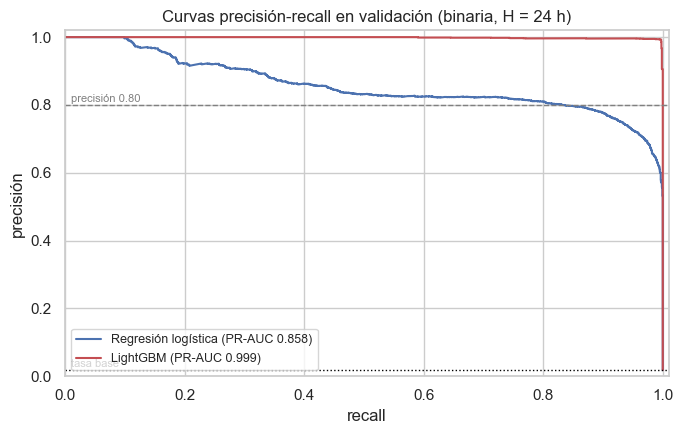

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, p in preds.items():
    prec, rec, _ = precision_recall_curve(va["y_bin"], p)
    ax.plot(rec, prec, color=MODEL_COLORS[name], label=f"{name} (PR-AUC {res_bin.loc[name, 'PR-AUC']:.3f})")
ax.axhline(0.80, color="gray", ls="--", lw=1)
ax.text(0.01, 0.81, "precisión 0.80", fontsize=8, color="gray")
ax.axhline(va["y_bin"].mean(), color="black", ls=":", lw=1)
ax.text(0.01, va["y_bin"].mean() + 0.01, "tasa base", fontsize=8)
ax.set(title="Curvas precisión-recall en validación (binaria, H = 24 h)", xlabel="recall", ylabel="precisión",
       xlim=(0, 1.01), ylim=(0, 1.02))
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
savefig(fig, "06_baseline_pr_curves")

## 2. Tarea multiclase: matriz de confusión

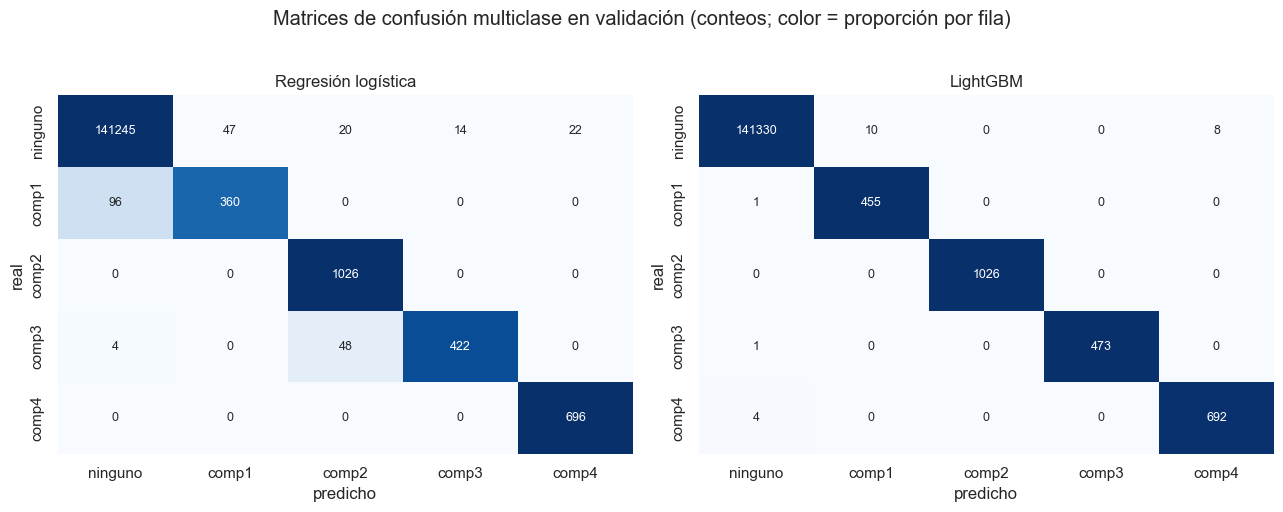

In [4]:
cms = {name: confusion(va["y_cls"], fit("y_cls", "multiclass").predict_proba(va[F]), CLASSES)
       for name, fit in FIT.items()}
pd.concat(cms, names=["modelo"]).to_csv(RESULTS_DIR / "baseline_val_confusion.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, cm) in zip(axes, cms.items()):
    sns.heatmap(cm.div(cm.sum(axis=1), axis=0), annot=cm.values, fmt="d", cmap="Blues", vmin=0, vmax=1,
                cbar=False, ax=ax, annot_kws={"fontsize": 9})
    ax.set(title=name, xlabel="predicho", ylabel="real")
fig.suptitle("Matrices de confusión multiclase en validación (conteos; color = proporción por fila)", y=1.02)
plt.tight_layout()
savefig(fig, "07_baseline_confusion")

## 3. ¿Por qué LightGBM es casi perfecto?

Una PR-AUC ≈ 1.0 con 2 % de positivos obliga a descartar una fuga:

- Las variables son causales (1.4).
- Las etiquetas no usan `PdM_maint` (1.3).
- Validación no interviene en el ajuste.

Ninguna de las tres explica el resultado. La explicación está en cómo se simuló el conjunto de datos.

Errores asociados en las 96 h previas: 1064;  exactamente a 24 h: 93.9%


,horas,p mediana,% sobre el umbral
"(0.0, 6.0]",654,9.718e-01,1.000
"(6.0, 12.0]",666,9.718e-01,1.000
"(12.0, 18.0]",666,9.719e-01,1.000
"(18.0, 24.0]",666,9.717e-01,1.000
"(24.0, 30.0]",666,9.568e-04,0.054
"(30.0, 36.0]",654,7.056e-04,0.014
"(36.0, 42.0]",654,5.812e-04,0.011
"(42.0, 48.0]",654,5.723e-04,0.009
"(48.0, 72.0]",2616,5.663e-04,0.005
"(72.0, inf]",136104,5.639e-04,0.002


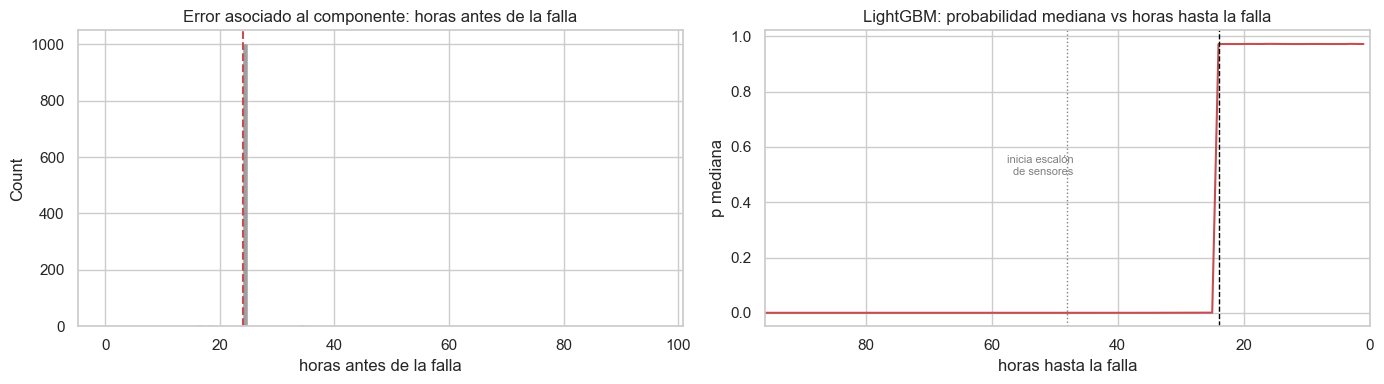

In [5]:
# (a) ¿Cuándo aparece el error asociado a cada componente respecto a la falla?
err, fail = load_errors(), load_failures()
ASSOC = {"comp1": ["error1"], "comp2": ["error2", "error3"], "comp3": ["error4"], "comp4": ["error5"]}
lags = []
for r in fail.itertuples():
    e = err[(err["machineID"] == r.machineID) & err["errorID"].isin(ASSOC[r.failure])]
    dt = (r.datetime - e["datetime"]) / pd.Timedelta(hours=1)
    lags.extend(dt[(dt >= 0) & (dt <= 96)].tolist())
lags = pd.Series(lags, name="horas antes de la falla")
print(f"Errores asociados en las 96 h previas: {len(lags)};  exactamente a 24 h: {(lags == 24).mean():.1%}")

# (b) Probabilidad predicha según las horas que faltan para la falla
p = preds["LightGBM"]
bins = [0, 6, 12, 18, 24, 30, 36, 42, 48, 72, np.inf]
by_htf = pd.Series(p).groupby(pd.cut(va["h_to_failure"].fillna(np.inf), bins).values, observed=True) \
    .agg(["size", "median", lambda x: (x >= res_bin.loc["LightGBM", "umbral"]).mean()])
by_htf.columns = ["horas", "p mediana", "% sobre el umbral"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(lags, bins=np.arange(0, 97, 1), ax=axes[0], color="gray")
axes[0].axvline(24, color="#c44e52", ls="--")
axes[0].set(title="Error asociado al componente: horas antes de la falla", xlabel="horas antes de la falla")
hb = pd.DataFrame({"h": va["h_to_failure"], "p": p}).dropna()
hb = hb[hb["h"] <= 96].groupby("h")["p"].median()
axes[1].plot(hb.index, hb.values, color="#c44e52")
axes[1].axvline(24, color="black", ls="--", lw=1)
axes[1].axvline(48, color="gray", ls=":", lw=1)
axes[1].set(title="LightGBM: probabilidad mediana vs horas hasta la falla", xlabel="horas hasta la falla",
            ylabel="p mediana", xlim=(96, 0))
axes[1].text(47, 0.5, "inicia escalón\nde sensores", ha="right", fontsize=8, color="gray")
plt.tight_layout()
savefig(fig, "08_baseline_why_perfect")
by_htf

**Lectura.** Dos regularidades de la simulación hacen el problema casi determinista con H = 24 h:

1. **El error asociado se emite exactamente 24 h antes de la falla** en el 94 % de los casos. Por eso un error reciente del tipo correspondiente coincide casi exactamente con la ventana positiva.
2. **Los sensores cambian en escalón 48 h antes** (1.1). Un sensor desplazado, junto con un error reciente, confirma que el error es precursor y no "de fondo".

LightGBM aprende esa interacción; la regresión logística, que es lineal, no puede. La probabilidad de LightGBM salta exactamente 24 h antes de la falla.

**No es una fuga**: toda la información está disponible en *t*. Pero tampoco es realista, y en una planta no cabría esperar este desempeño.

## Resumen

Los números exactos están en `entrega1/results/baseline_val_binary.csv` y `baseline_val_confusion.csv`.

- **Binaria (validación):**

  | modelo | PR-AUC | ROC-AUC | recall @ P ≥ 0.80 |
  |---|---|---|---|
  | Regresión logística | 0.86 | 0.998 | 0.84 |
  | LightGBM | 0.999 | 1.000 | 1.00 |

- **Multiclase:** LightGBM casi no se equivoca. Los errores de la logística se concentran en comp1 → "ninguno" y comp3 → comp2.
- **Diagnóstico:** el desempeño casi perfecto se explica por la simulación (errores 24 h antes de la falla, escalón de sensores 48 h antes), no por una fuga.